In [10]:
#pip install scikit-learn
#%pip install tensorflow

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import warnings
warnings.filterwarnings("ignore")

In [12]:
df = pd.read_csv("eirgrid_processed.csv", parse_dates=["timestamp"])
df = df.set_index("timestamp")

print(f"Raw shape: {df.shape}")

# Resample to hourly — reduces 446k rows to ~111k for LSTM efficiency
df_hourly = df[["Wind Generation (MW)"]].resample("h").mean().dropna()

print(f"Hourly shape: {df_hourly.shape}")
df_hourly.head()

Raw shape: (446193, 11)
Hourly shape: (111571, 1)


,Wind Generation (MW)
timestamp,
2014-01-08 00:00:00,1216.00
2014-01-08 01:00:00,1080.25
2014-01-08 02:00:00,943.50
2014-01-08 03:00:00,780.00
2014-01-08 04:00:00,699.00


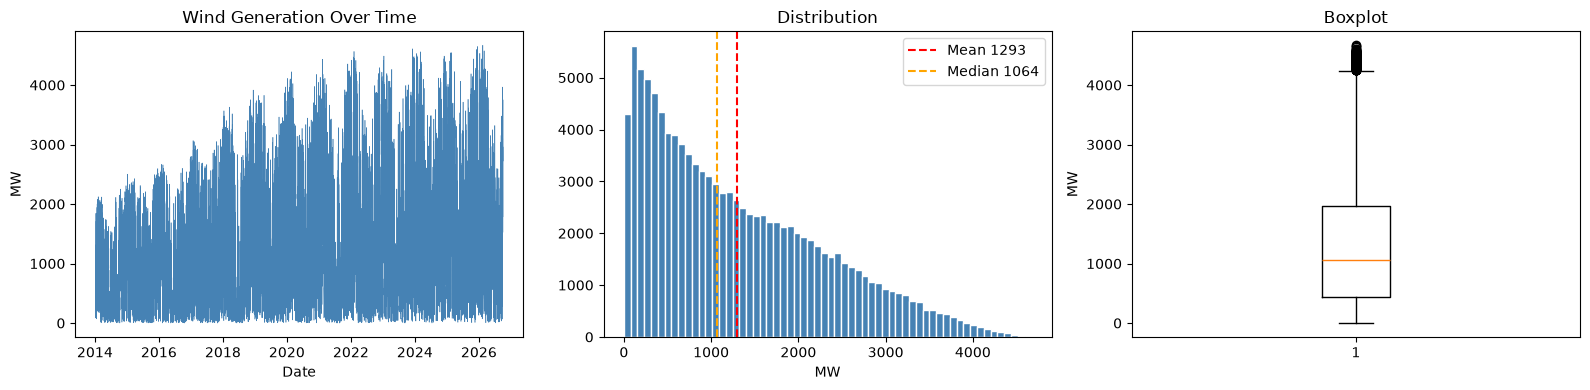

Skewness: 0.764
Mean:     1293.4 MW
Median:   1064.0 MW
Std:      1000.4 MW
Min:      0.0 | Max: 4669.5


In [13]:
wind = df_hourly["Wind Generation (MW)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(wind, color="steelblue", linewidth=0.4)
axes[0].set_title("Wind Generation Over Time")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("MW")

axes[1].hist(wind, bins=60, color="steelblue", edgecolor="white")
axes[1].set_title("Distribution")
axes[1].set_xlabel("MW")
axes[1].axvline(wind.mean(),   color="red",    linestyle="--", label=f"Mean {wind.mean():.0f}")
axes[1].axvline(wind.median(), color="orange", linestyle="--", label=f"Median {wind.median():.0f}")
axes[1].legend()

axes[2].boxplot(wind.dropna(), vert=True)
axes[2].set_title("Boxplot")
axes[2].set_ylabel("MW")

plt.tight_layout()
plt.show()

print(f"Skewness: {wind.skew():.3f}")
print(f"Mean:     {wind.mean():.1f} MW")
print(f"Median:   {wind.median():.1f} MW")
print(f"Std:      {wind.std():.1f} MW")
print(f"Min:      {wind.min():.1f} | Max: {wind.max():.1f}")